In [1]:
# Setup -- clean data, ACTIVE bouts only (no bout on either side of a > 10 s gap)
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if (Path.cwd().parent / "clean_data").exists() else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))

PX_TO_MM = 3.67               # same scale as the original AllFish plot
BIN_S = 2.0                   # bouts are sampled at their onsets (~1.2 s apart), so time is binned
EXCLUDE_CENTROID_OUT = True   # closest available analogue of the original `dots_out < 1` filter

d = pd.read_csv(ROOT / "clean_data" / "bouts_clean.csv")
a = d[d.active].copy()
print(f"{len(d):,} bouts -> {len(a):,} active ({100 * len(a) / len(d):.1f}%), {a.fish_id.nunique()} fish")

71,937 bouts -> 69,572 active (96.7%), 15 fish


In [2]:
# Per-bout condition and block clock.
#  - t_blk = seconds since the EXACT block onset (frame grid: 1500-frame pause + 1800-frame stimulus,
#    identical for all fish), i.e. the original's frame_count_stimulus / 30 -- not "since the first
#    bout of the block".
#  - condition = total dots on screen (left + right merged, as the original d1s3.5 labels were)
#    x motion. Pauses carry no dots, so there is no distance to plot for them.
#  - the clean data has the dot CENTROID, not each dot, so the original "no dot outside the dish"
#    filter becomes "centroid inside the dish" -- a looser version of the same rule.
a["n_dots"] = (a.n_dots_left.fillna(0) + a.n_dots_right.fillna(0)).astype(int)
st = a[(a.stimulus != "inter_stim_pause") & a.dot_dist_px.notna()].copy()
st["cond_label"] = [f"d{n}s{'3.5' if m else '0'}" for n, m in zip(st.n_dots, st.moving)]
if EXCLUDE_CENTROID_OUT:
    import evaluate as E, fit_MLP_border as MB          # physical dish, same geometry as the models
    recs = MB.build_border_records(E.load_bouts())
    dish = pd.DataFrame({f: dict(cx=r.dish_cx, cy=r.dish_cy, R=r.dish_R) for f, r in recs.items()}).T
    g = st.join(dish, on="fish_id")
    out = (np.hypot(g.dot_cx - g.cx, g.dot_cy - g.cy) > g.R).to_numpy()
    print(f"dropped {100 * out.mean():.1f}% of stimulus bouts: dot centroid outside the dish")
    st = st[~out]
st["dist_mm"] = st.dot_dist_px / PX_TO_MM
st["tbin"] = (np.floor(st.t_blk / BIN_S) + 0.5) * BIN_S          # bin centre, seconds
print(st.groupby("cond_label").agg(bouts=("fish_id", "size"), fish=("fish_id", "nunique"))
      .loc[["d1s3.5", "d2s3.5", "d4s3.5", "d6s3.5", "d8s3.5", "d1s0", "d4s0", "d8s0"]].to_string())

dropped 11.4% of stimulus bouts: dot centroid outside the dish
            bouts  fish
cond_label             
d1s3.5       4505    15
d2s3.5       4347    15
d4s3.5       4838    15
d6s3.5       4952    15
d8s3.5       4071    15
d1s0         4020    15
d4s0         4084    15
d8s0         4234    15


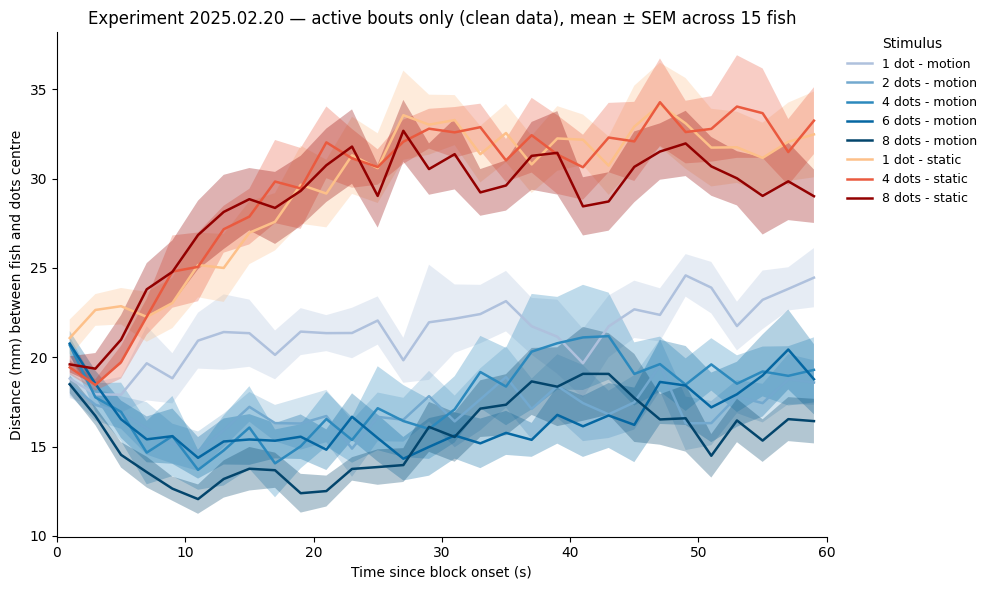

In [3]:
# --- Distance to the dots' centre over the block, ACTIVE bouts only -------------------------------
# Same design as the original AllFish plot: one line per condition, per-fish mean over that fish's
# blocks first, then mean +/- SEM across fish; gradient palettes by dot count (PuBu motion, OrRd
# static). Differences: bout onsets instead of every frame (hence BIN_S bins), active bouts only,
# no pause line (no dots on screen).
import re
# Same gradients as the original (PuBu motion, OrRd static, darker = more dots), but sampled from
# 35% to 95% of each colormap: the original's lightest step drew "1 dot - motion" near-white.
_pal = lambda name, n: [plt.get_cmap(name)(x) for x in np.linspace(0.35, 0.95, n)]

def parse_stim(stim):
    m = re.match(r"d(\d+)s([\d\.]+)$", stim)
    return (int(m.group(1)), float(m.group(2))) if m else (None, None)

def stim_label(stim):
    n, speed = parse_stim(stim)
    return f"{n} dot{'s' if n != 1 else ''} - {'static' if speed == 0 else 'motion'}"

stimuli_order = ["d1s3.5", "d2s3.5", "d4s3.5", "d6s3.5", "d8s3.5", "d1s0", "d4s0", "d8s0"]
motion = [s for s in stimuli_order if parse_stim(s)[1] != 0]
static = [s for s in stimuli_order if parse_stim(s)[1] == 0]
color_map = {**dict(zip(sorted(motion, key=lambda s: parse_stim(s)[0]), _pal("PuBu", len(motion)))),
             **dict(zip(sorted(static, key=lambda s: parse_stim(s)[0]), _pal("OrRd", len(static))))}

fig, ax = plt.subplots(figsize=(10, 6))
for stim in stimuli_order:
    s = st[st.cond_label == stim]
    per_fish = s.groupby(["fish_id", "tbin"]).dist_mm.mean().reset_index()   # over that fish's blocks
    grp = per_fish.groupby("tbin").dist_mm
    mu, sem = grp.mean(), grp.sem()
    ax.plot(mu.index, mu, label=stim_label(stim), color=color_map[stim], lw=1.8)
    ax.fill_between(mu.index, mu - sem, mu + sem, alpha=0.3, color=color_map[stim], edgecolor="none")

ax.set_xlabel("Time since block onset (s)")
ax.set_ylabel("Distance (mm) between fish and dots centre")
ax.set_xlim(0, 60)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.set_title("Experiment 2025.02.20 — active bouts only (clean data), mean ± SEM across 15 fish")
plt.subplots_adjust(right=0.78)
ax.legend(title="Stimulus", loc="upper left", fontsize=9, bbox_to_anchor=(1.02, 1),
          borderaxespad=0., frameon=False, title_fontsize=10)
plt.tight_layout()
plt.show()

  S1_dta_fold4.pt: 3 rollouts
dropped 9.0% of generated stimulus bouts: dot centroid outside the dish


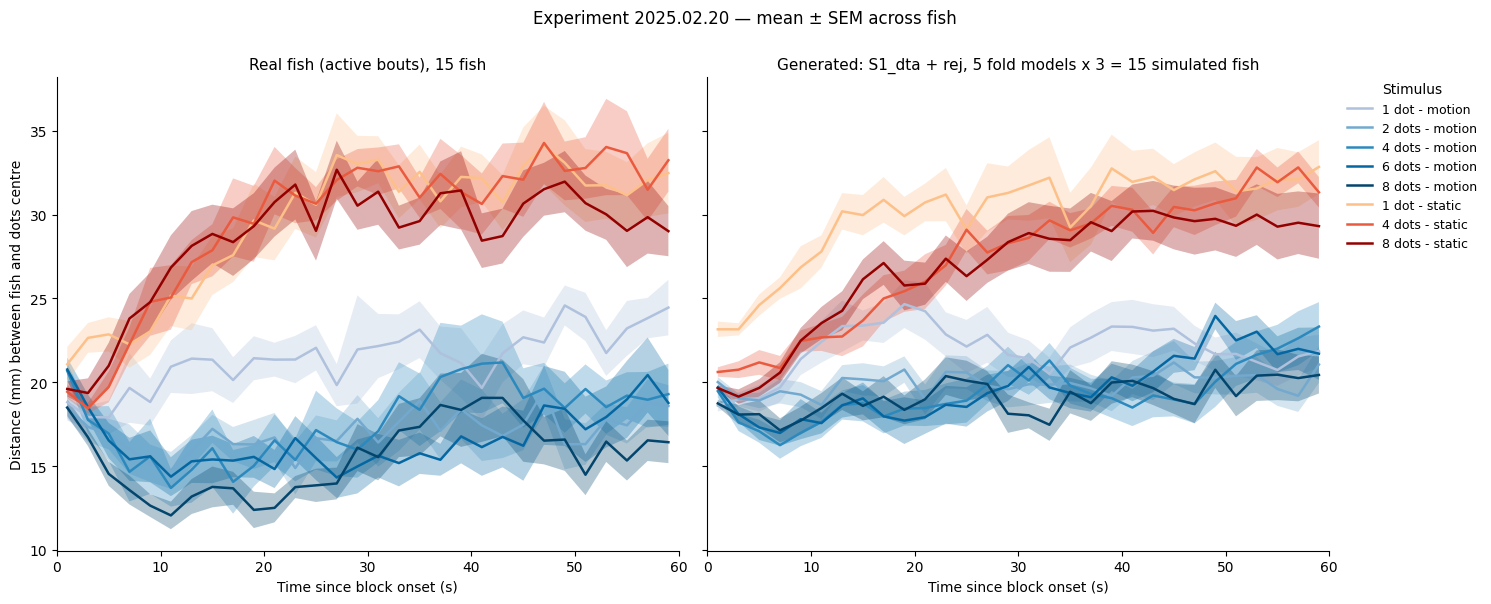

mean distance to the dots (mm): per-fish mean, then mean across fish
            real 0-2 s  gen 0-2 s  real 20-60 s  gen 20-60 s
cond_label                                                  
d1s3.5            18.8       18.6          22.4         22.1
d2s3.5            18.5       20.0          17.4         20.0
d4s3.5            20.7       19.5          18.7         20.2
d6s3.5            20.8       19.7          16.7         20.5
d8s3.5            18.5       18.7          16.4         19.5
d1s0              21.1       23.2          31.8         31.5
d4s0              19.4       20.6          31.6         29.8
d8s0              19.6       19.7          30.2         28.9


In [ ]:
# --- The same plot from GENERATED trajectories: S1_dta + rej -------------------------------------
# Generated the way the rollout tool does it: each simulated fish swims the whole recorded programme
# on its OWN clock (the stimulus advances with the intervals the model emits), and the dot track is
# re-anchored to that fish's pose at every block onset -- the rig's rule. No real record is involved:
# the relative programme is the same for every fish. There is no all-data S1_dta model (the ordering
# sweep trained folds only), so the 5 fold models -- each a population model trained on 12 of the 15
# fish -- give R_PER_MODEL rollouts each: 15 simulated fish, matching the 15 real ones. Distance is to
# the dots each rollout actually saw; the centroid-outside-dish rule is applied as for the real data.
import io, json, contextlib
import fit_MLP_mix as MX, stim_program as SP, stim_rollout as SR, tool_reference as TR
ARM, R_PER_MODEL = "S1_dta", 3
CKPT = ROOT / "Model" / "model1_checkpoints"
REJ = {"d0": 2.0, "d1": 10.0, "max_draws": 20}
MX._numpy2_unpickle_compat()
program = SP.load_program(str(ROOT / "assets" / "stimulus"
                              / "2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz"))
dish_sim = SR.default_dish()                                   # median PHYSICAL dish of the 15
ref = TR.load_reference(str(ROOT / "assets" / "real_reference.npz"))   # real start-pose sampler
folds = sorted(e["file"] for e in json.loads((CKPT / "manifest_model1.json").read_text())
               if e["file"].startswith(ARM + "_fold"))
rows = []
for k, ck in enumerate(folds):
    m = MX.load_mix(str(CKPT / ck))
    m._cfg_feat = {**m._cfg_feat, "wall_reject": REJ}
    with contextlib.redirect_stdout(io.StringIO()):            # rollout_many prints a line per fish
        rolls = SR.rollout_many(m, program, R_PER_MODEL, seed=k, dish=dish_sim,
                                pose_sampler=ref.sample_start_pose)
    for r, g in enumerate(rolls):
        b = np.asarray(g["block_id"])
        rows.append(pd.DataFrame(dict(
            fish_id=k * R_PER_MODEL + r,                       # replicate unit = one simulated fish
            t_blk=(np.asarray(g["frame_onset"]) - program.starts[b]) / program.fps,
            is_stim=program.is_stim_of[b], n_dots=program.n_dots_of[b], moving=program.moving_of[b],
            gx=g["x_px"], gy=g["y_px"], gcx=g["dot_cx"], gcy=g["dot_cy"])))
    print(f"\r  {ck}: {R_PER_MODEL} rollouts", end="", flush=True)
print()
gen = pd.concat(rows, ignore_index=True)
gen = gen[gen.is_stim & gen.gcx.notna()].copy()
gen["cond_label"] = [f"d{int(n)}s{'3.5' if mv else '0'}" for n, mv in zip(gen.n_dots, gen.moving)]
if EXCLUDE_CENTROID_OUT:
    cx, cy, R = dish_sim
    out = (np.hypot(gen.gcx - cx, gen.gcy - cy) > R).to_numpy()
    print(f"dropped {100 * out.mean():.1f}% of generated stimulus bouts: dot centroid outside the dish")
    gen = gen[~out]
gen["dist_mm"] = np.hypot(gen.gx - gen.gcx, gen.gy - gen.gcy) / PX_TO_MM
gen["tbin"] = (np.floor(gen.t_blk / BIN_S) + 0.5) * BIN_S

def draw(df, ax, title):
    for stim in stimuli_order:
        s = df[df.cond_label == stim]
        per_fish = s.groupby(["fish_id", "tbin"]).dist_mm.mean().reset_index()   # over blocks
        grp = per_fish.groupby("tbin").dist_mm
        mu, sem = grp.mean(), grp.sem()
        ax.plot(mu.index, mu, label=stim_label(stim), color=color_map[stim], lw=1.8)
        ax.fill_between(mu.index, mu - sem, mu + sem, alpha=0.3, color=color_map[stim], edgecolor="none")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Time since block onset (s)")
    ax.set_xlim(0, 60)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)

fig, ax = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
draw(st, ax[0], "Real fish (active bouts), 15 fish")
draw(gen, ax[1], f"Generated: {ARM} + rej, {len(folds)} fold models x {R_PER_MODEL} = "
                 f"{gen.fish_id.nunique()} simulated fish")
ax[0].set_ylabel("Distance (mm) between fish and dots centre")
ax[1].legend(title="Stimulus", loc="upper left", fontsize=9, bbox_to_anchor=(1.02, 1),
             borderaxespad=0., frameon=False, title_fontsize=10)
fig.suptitle("Experiment 2025.02.20 \u2014 mean \u00b1 SEM across fish", y=1.0)
plt.tight_layout()
plt.show()

def window(df, lo, hi):
    w = df[(df.t_blk >= lo) & (df.t_blk < hi)]
    return w.groupby(["cond_label", "fish_id"]).dist_mm.mean().groupby("cond_label").mean()
print("mean distance to the dots (mm): per-fish mean, then mean across fish")
print(pd.DataFrame({"real 0-2 s": window(st, 0, 2), "gen 0-2 s": window(gen, 0, 2),
                    "real 20-60 s": window(st, 20, 60), "gen 20-60 s": window(gen, 20, 60)})
      .loc[stimuli_order].round(1).to_string())

  S1_adt_fold4.pt: 3 rollouts
dropped 9.7% of generated stimulus bouts: dot centroid outside the dish


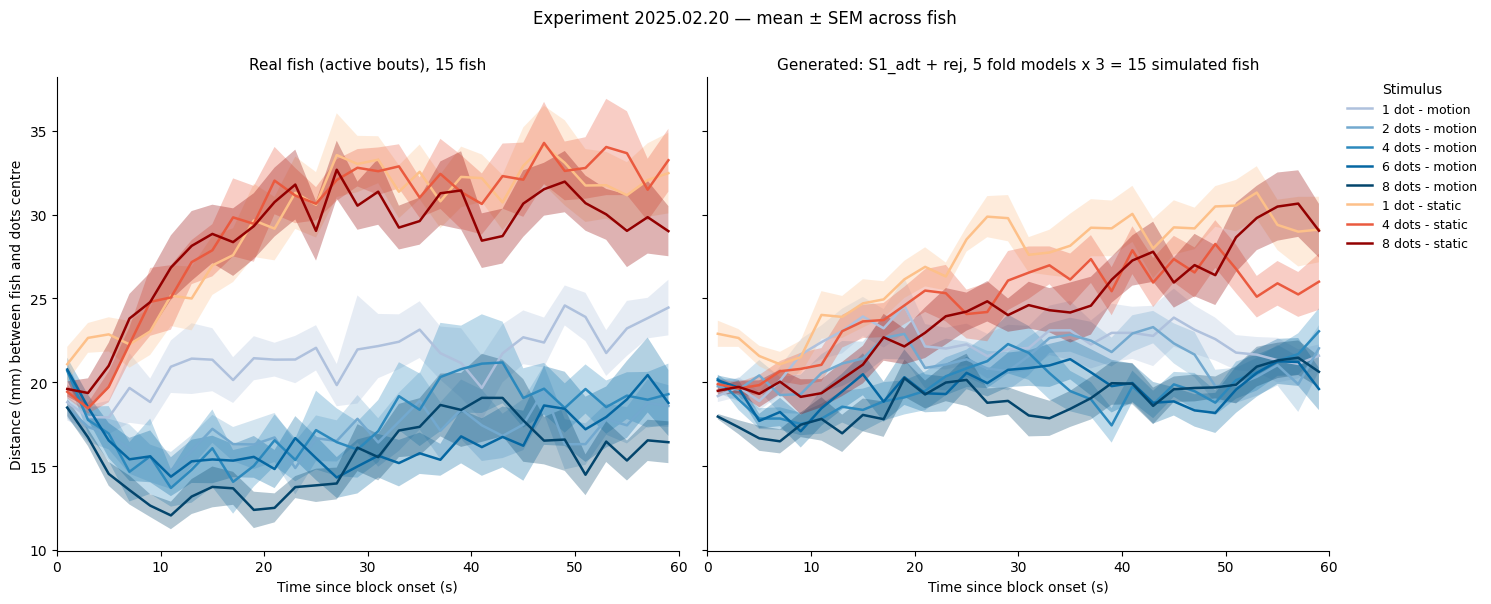

mean distance to the dots (mm): per-fish mean, then mean across fish
            real 0-2 s  gen 0-2 s  real 20-60 s  gen 20-60 s
cond_label                                                  
d1s3.5            18.8       19.2          22.4         22.3
d2s3.5            18.5       19.8          17.4         21.5
d4s3.5            20.7       20.2          18.7         20.3
d6s3.5            20.8       20.1          16.7         20.1
d8s3.5            18.5       18.0          16.4         19.6
d1s0              21.1       22.9          31.8         29.0
d4s0              19.4       19.9          31.6         26.1
d8s0              19.6       19.5          30.2         26.4


In [7]:
# --- The same plot from GENERATED trajectories: S1_dta + rej -------------------------------------
# Generated the way the rollout tool does it: each simulated fish swims the whole recorded programme
# on its OWN clock (the stimulus advances with the intervals the model emits), and the dot track is
# re-anchored to that fish's pose at every block onset -- the rig's rule. No real record is involved:
# the relative programme is the same for every fish. There is no all-data S1_dta model (the ordering
# sweep trained folds only), so the 5 fold models -- each a population model trained on 12 of the 15
# fish -- give R_PER_MODEL rollouts each: 15 simulated fish, matching the 15 real ones. Distance is to
# the dots each rollout actually saw; the centroid-outside-dish rule is applied as for the real data.
import io, json, contextlib
import fit_MLP_mix as MX, stim_program as SP, stim_rollout as SR, tool_reference as TR
ARM, R_PER_MODEL = "S1_adt", 3
CKPT = ROOT / "Model" / "model1_checkpoints"
REJ = {"d0": 2.0, "d1": 10.0, "max_draws": 20}
MX._numpy2_unpickle_compat()
program = SP.load_program(str(ROOT / "assets" / "stimulus"
                              / "2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz"))
dish_sim = SR.default_dish()                                   # median PHYSICAL dish of the 15
ref = TR.load_reference(str(ROOT / "assets" / "real_reference.npz"))   # real start-pose sampler
folds = sorted(e["file"] for e in json.loads((CKPT / "manifest_model1.json").read_text())
               if e["file"].startswith(ARM + "_fold"))
rows = []
for k, ck in enumerate(folds):
    m = MX.load_mix(str(CKPT / ck))
    m._cfg_feat = {**m._cfg_feat, "wall_reject": REJ}
    with contextlib.redirect_stdout(io.StringIO()):            # rollout_many prints a line per fish
        rolls = SR.rollout_many(m, program, R_PER_MODEL, seed=k, dish=dish_sim,
                                pose_sampler=ref.sample_start_pose)
    for r, g in enumerate(rolls):
        b = np.asarray(g["block_id"])
        rows.append(pd.DataFrame(dict(
            fish_id=k * R_PER_MODEL + r,                       # replicate unit = one simulated fish
            t_blk=(np.asarray(g["frame_onset"]) - program.starts[b]) / program.fps,
            is_stim=program.is_stim_of[b], n_dots=program.n_dots_of[b], moving=program.moving_of[b],
            gx=g["x_px"], gy=g["y_px"], gcx=g["dot_cx"], gcy=g["dot_cy"])))
    print(f"\r  {ck}: {R_PER_MODEL} rollouts", end="", flush=True)
print()
gen = pd.concat(rows, ignore_index=True)
gen = gen[gen.is_stim & gen.gcx.notna()].copy()
gen["cond_label"] = [f"d{int(n)}s{'3.5' if mv else '0'}" for n, mv in zip(gen.n_dots, gen.moving)]
if EXCLUDE_CENTROID_OUT:
    cx, cy, R = dish_sim
    out = (np.hypot(gen.gcx - cx, gen.gcy - cy) > R).to_numpy()
    print(f"dropped {100 * out.mean():.1f}% of generated stimulus bouts: dot centroid outside the dish")
    gen = gen[~out]
gen["dist_mm"] = np.hypot(gen.gx - gen.gcx, gen.gy - gen.gcy) / PX_TO_MM
gen["tbin"] = (np.floor(gen.t_blk / BIN_S) + 0.5) * BIN_S

def draw(df, ax, title):
    for stim in stimuli_order:
        s = df[df.cond_label == stim]
        per_fish = s.groupby(["fish_id", "tbin"]).dist_mm.mean().reset_index()   # over blocks
        grp = per_fish.groupby("tbin").dist_mm
        mu, sem = grp.mean(), grp.sem()
        ax.plot(mu.index, mu, label=stim_label(stim), color=color_map[stim], lw=1.8)
        ax.fill_between(mu.index, mu - sem, mu + sem, alpha=0.3, color=color_map[stim], edgecolor="none")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Time since block onset (s)")
    ax.set_xlim(0, 60)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)

fig, ax = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
draw(st, ax[0], "Real fish (active bouts), 15 fish")
draw(gen, ax[1], f"Generated: {ARM} + rej, {len(folds)} fold models x {R_PER_MODEL} = "
                 f"{gen.fish_id.nunique()} simulated fish")
ax[0].set_ylabel("Distance (mm) between fish and dots centre")
ax[1].legend(title="Stimulus", loc="upper left", fontsize=9, bbox_to_anchor=(1.02, 1),
             borderaxespad=0., frameon=False, title_fontsize=10)
fig.suptitle("Experiment 2025.02.20 \u2014 mean \u00b1 SEM across fish", y=1.0)
plt.tight_layout()
plt.show()

def window(df, lo, hi):
    w = df[(df.t_blk >= lo) & (df.t_blk < hi)]
    return w.groupby(["cond_label", "fish_id"]).dist_mm.mean().groupby("cond_label").mean()
print("mean distance to the dots (mm): per-fish mean, then mean across fish")
print(pd.DataFrame({"real 0-2 s": window(st, 0, 2), "gen 0-2 s": window(gen, 0, 2),
                    "real 20-60 s": window(st, 20, 60), "gen 20-60 s": window(gen, 20, 60)})
      .loc[stimuli_order].round(1).to_string())

  S1_adt_z2_fold4.pt: 3 rollouts
dropped 8.0% of generated stimulus bouts: dot centroid outside the dish


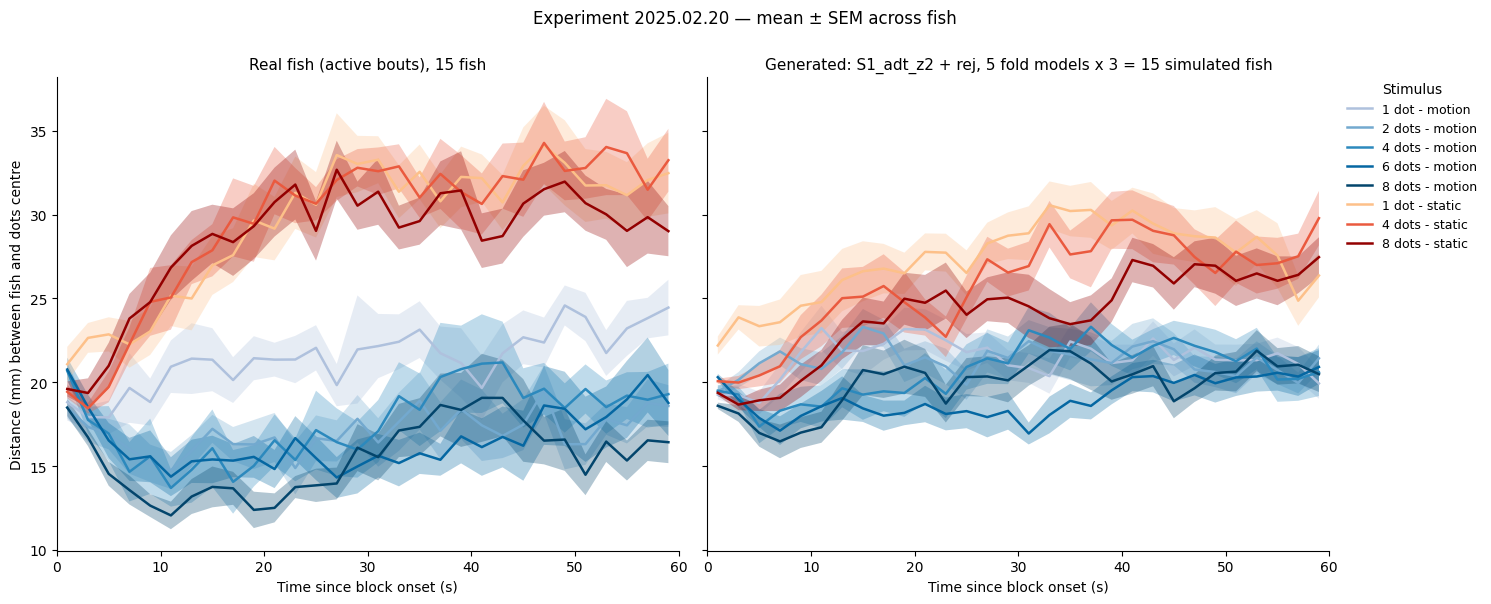

mean distance to the dots (mm): per-fish mean, then mean across fish
            real 0-2 s  gen 0-2 s  real 20-60 s  gen 20-60 s
cond_label                                                  
d1s3.5            18.8       19.3          22.4         21.6
d2s3.5            18.5       19.4          17.4         21.3
d4s3.5            20.7       19.5          18.7         21.6
d6s3.5            20.8       20.3          16.7         19.4
d8s3.5            18.5       18.6          16.4         20.6
d1s0              21.1       22.2          31.8         28.5
d4s0              19.4       20.1          31.6         27.4
d8s0              19.6       19.4          30.2         25.5


In [6]:
# --- The same plot from GENERATED trajectories: S1_dta + rej -------------------------------------
# Generated the way the rollout tool does it: each simulated fish swims the whole recorded programme
# on its OWN clock (the stimulus advances with the intervals the model emits), and the dot track is
# re-anchored to that fish's pose at every block onset -- the rig's rule. No real record is involved:
# the relative programme is the same for every fish. There is no all-data S1_dta model (the ordering
# sweep trained folds only), so the 5 fold models -- each a population model trained on 12 of the 15
# fish -- give R_PER_MODEL rollouts each: 15 simulated fish, matching the 15 real ones. Distance is to
# the dots each rollout actually saw; the centroid-outside-dish rule is applied as for the real data.
import io, json, contextlib
import fit_MLP_mix as MX, stim_program as SP, stim_rollout as SR, tool_reference as TR
ARM, R_PER_MODEL = "S1_adt_z2", 3
CKPT = ROOT / "Model" / "model2z_checkpoints"
REJ = {"d0": 2.0, "d1": 10.0, "max_draws": 20}
MX._numpy2_unpickle_compat()
program = SP.load_program(str(ROOT / "assets" / "stimulus"
                              / "2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz"))
dish_sim = SR.default_dish()                                   # median PHYSICAL dish of the 15
ref = TR.load_reference(str(ROOT / "assets" / "real_reference.npz"))   # real start-pose sampler
folds = sorted(e["file"] for e in json.loads((CKPT / "manifest_model1.json").read_text())
               if e["file"].startswith(ARM + "_fold"))
rows = []
for k, ck in enumerate(folds):
    m = MX.load_mix(str(CKPT / ck))
    m._cfg_feat = {**m._cfg_feat, "wall_reject": REJ}
    with contextlib.redirect_stdout(io.StringIO()):            # rollout_many prints a line per fish
        rolls = SR.rollout_many(m, program, R_PER_MODEL, seed=k, dish=dish_sim,
                                pose_sampler=ref.sample_start_pose)
    for r, g in enumerate(rolls):
        b = np.asarray(g["block_id"])
        rows.append(pd.DataFrame(dict(
            fish_id=k * R_PER_MODEL + r,                       # replicate unit = one simulated fish
            t_blk=(np.asarray(g["frame_onset"]) - program.starts[b]) / program.fps,
            is_stim=program.is_stim_of[b], n_dots=program.n_dots_of[b], moving=program.moving_of[b],
            gx=g["x_px"], gy=g["y_px"], gcx=g["dot_cx"], gcy=g["dot_cy"])))
    print(f"\r  {ck}: {R_PER_MODEL} rollouts", end="", flush=True)
print()
gen = pd.concat(rows, ignore_index=True)
gen = gen[gen.is_stim & gen.gcx.notna()].copy()
gen["cond_label"] = [f"d{int(n)}s{'3.5' if mv else '0'}" for n, mv in zip(gen.n_dots, gen.moving)]
if EXCLUDE_CENTROID_OUT:
    cx, cy, R = dish_sim
    out = (np.hypot(gen.gcx - cx, gen.gcy - cy) > R).to_numpy()
    print(f"dropped {100 * out.mean():.1f}% of generated stimulus bouts: dot centroid outside the dish")
    gen = gen[~out]
gen["dist_mm"] = np.hypot(gen.gx - gen.gcx, gen.gy - gen.gcy) / PX_TO_MM
gen["tbin"] = (np.floor(gen.t_blk / BIN_S) + 0.5) * BIN_S

def draw(df, ax, title):
    for stim in stimuli_order:
        s = df[df.cond_label == stim]
        per_fish = s.groupby(["fish_id", "tbin"]).dist_mm.mean().reset_index()   # over blocks
        grp = per_fish.groupby("tbin").dist_mm
        mu, sem = grp.mean(), grp.sem()
        ax.plot(mu.index, mu, label=stim_label(stim), color=color_map[stim], lw=1.8)
        ax.fill_between(mu.index, mu - sem, mu + sem, alpha=0.3, color=color_map[stim], edgecolor="none")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Time since block onset (s)")
    ax.set_xlim(0, 60)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)

fig, ax = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
draw(st, ax[0], "Real fish (active bouts), 15 fish")
draw(gen, ax[1], f"Generated: {ARM} + rej, {len(folds)} fold models x {R_PER_MODEL} = "
                 f"{gen.fish_id.nunique()} simulated fish")
ax[0].set_ylabel("Distance (mm) between fish and dots centre")
ax[1].legend(title="Stimulus", loc="upper left", fontsize=9, bbox_to_anchor=(1.02, 1),
             borderaxespad=0., frameon=False, title_fontsize=10)
fig.suptitle("Experiment 2025.02.20 \u2014 mean \u00b1 SEM across fish", y=1.0)
plt.tight_layout()
plt.show()

def window(df, lo, hi):
    w = df[(df.t_blk >= lo) & (df.t_blk < hi)]
    return w.groupby(["cond_label", "fish_id"]).dist_mm.mean().groupby("cond_label").mean()
print("mean distance to the dots (mm): per-fish mean, then mean across fish")
print(pd.DataFrame({"real 0-2 s": window(st, 0, 2), "gen 0-2 s": window(gen, 0, 2),
                    "real 20-60 s": window(st, 20, 60), "gen 20-60 s": window(gen, 20, 60)})
      .loc[stimuli_order].round(1).to_string())